# Q3. Time series decision challenge
Weekly units sold, weeks 1-12. All logic is in `../q3_core.py` (shared with `run_q3.py`, the Streamlit page and the unit tests).

**Assumptions**: the 12 values are consecutive weekly observations; no timestamps were supplied, so none are invented. Demand = units sold (stock-outs would hide true demand).

In [1]:
import sys, unittest
sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from q3_core import *
pd.set_option("display.width", 200)
print("sales:", SALES)

sales: [120, 130, 125, 140, 152, 149, 165, 170, 190, 185, 205, 215]


##  Week-13 forecasts

In [ ]:
fc = forecast_next(SALES)
print(f"Week {fc['target_week']}  naive last value = {fc[METHODS[0]]:.2f}   trailing 3-week average = {fc[METHODS[1]]:.2f}")

Week 13  naive last value = 215.00   trailing 3-week average = 201.67


## (b) Expanding-window one-step backtest, weeks 5-12
To score week *t*, both methods see weeks 1..*t*-1 only (window grows 4 to 11 observations).

In [3]:
bt = expanding_backtest(SALES)
print(bt.round(2).to_string(index=False))
s = backtest_summary(bt)
print()
print(f"Naive MAE = {s['naive_mae']:.3f}   3-week-average MAE = {s['avg_mae']:.3f}   -> baseline: {select_baseline(s['naive_mae'], s['avg_mae'])}")
print(f"Naive closer in {s['naive_wins']}/{s['n_weeks']} weeks; mean signed error (actual-forecast): naive {s['naive_bias']:+.2f}, average {s['avg_bias']:+.2f}")

 Week  Training weeks  Actual  Naive forecast  Naive error  Naive absolute error  3-week average forecast  3-week average error  3-week average absolute error
    5               4   152.0           140.0         12.0                  12.0                   131.67                 20.33                          20.33
    6               5   149.0           152.0         -3.0                   3.0                   139.00                 10.00                          10.00
    7               6   165.0           149.0         16.0                  16.0                   147.00                 18.00                          18.00
    8               7   170.0           165.0          5.0                   5.0                   155.33                 14.67                          14.67
    9               8   190.0           170.0         20.0                  20.0                   161.33                 28.67                          28.67
   10               9   185.0           190.0 

### Why shuffling invalidates the test
A shuffled/random split lets weeks *after* the target inform its forecast (leakage) and destroys the trend and autocorrelation the methods rely on. Two demonstrations:

In [4]:
# 1) leakage: 'forecast' week t from its two neighbours, one of which is in the future
print(f"neighbour-average MAE (weeks 5-11, uses the future) = {leaky_neighbour_mae(SALES):.2f}  vs honest naive MAE = {s['naive_mae']:.2f}")
# 2) order matters: the same numbers shuffled give a different 'result'
rng = np.random.default_rng(0)
shuffled = np.array(SALES, float); rng.shuffle(shuffled)
print("shuffled series:", shuffled.astype(int).tolist())
print(f"naive MAE on shuffled series = {backtest_summary(expanding_backtest(shuffled))['naive_mae']:.2f} (not a measure of real forecasting skill)")
# 3) guarantee: editing week 12 cannot change any forecast for weeks 5-11
y2 = list(SALES); y2[-1] = 9999
cols = ["Naive forecast", "3-week average forecast"]
pd.testing.assert_frame_equal(bt.iloc[:-1][cols], expanding_backtest(y2).iloc[:-1][cols])
print("no-leakage check passed: past forecasts unchanged when week 12 is altered")

neighbour-average MAE (weeks 5-11, uses the future) = 8.57  vs honest naive MAE = 11.38
shuffled series: [185, 125, 170, 152, 149, 215, 120, 140, 165, 205, 190, 130]
naive MAE on shuffled series = 40.50 (not a measure of real forecasting skill)
no-leakage check passed: past forecasts unchanged when week 12 is altered


## (c) Missing weekly dates and duplicate dates
With no timestamps the check cannot observe gaps; it says so instead of reporting a false all-clear. The detector is exercised on a fault-injected dated input.

In [5]:
r0 = audit_weekly_dates(None, n_obs=len(SALES), assumed_start="2024-01-07")
print(r0["mode"], "->", r0["note"]); print()
dated = ["2024-01-07", "2024-01-14", "2024-01-14", "2024-01-28", "2024-02-06", "not-a-date"]
r = audit_weekly_dates(dated)
print("input:", dated)
print("invalid:", r["invalid"], "| exact duplicates:", [str(d.date()) for d in r["exact_duplicates"]],
      "| missing weeks (week ending):", [str(d.date()) for d in r["missing_weeks"]],
      "| off-cadence weekdays:", r["off_cadence"], "| ok:", r["ok"])
print("clean 12-week index ok:", audit_weekly_dates(pd.date_range("2024-01-07", periods=12, freq="W-SUN"))["ok"])

assumed (no timestamps supplied) -> No timestamps: gaps/duplicates cannot be observed. Consecutive weekly spacing is an ASSUMPTION, so zero issues here is by construction, not evidence.

input: ['2024-01-07', '2024-01-14', '2024-01-14', '2024-01-28', '2024-02-06', 'not-a-date']
invalid: 1 | exact duplicates: ['2024-01-14'] | missing weeks (week ending): ['2024-01-21', '2024-02-04'] | off-cadence weekdays: 1 | ok: False
clean 12-week index ok: True


## (d) Demand-alert rule tied to backtest uncertainty
Band = forecast ± the conformal-rank quantile of the chosen method's backtest absolute errors: the ceil((n+1)·coverage)-th smallest error. If n is too small for that rank, the max error is used and no coverage is claimed.

In [6]:
chosen = select_baseline(s["naive_mae"], s["avg_mae"])
col = "Naive absolute error" if chosen == METHODS[0] else "3-week average absolute error"
f13 = fc[chosen]
for cov in (0.80, 0.90):
    t = alert_tolerance(bt[col], cov)
    print(f"coverage target {cov:.0%}: half-width {t['half_width']:.1f}, rank {t['rank_used']} of {t['n_errors']}, "
          f"guarantee available: {t['guarantee_available']} (needs >= {t['min_errors_needed']} errors)")
print()
for actual in (225, 250, 190):
    a = demand_alert(f13, actual, bt[col], 0.80)
    print(f"week 13 forecast {f13:.0f}, band [{a['lower']:.0f}, {a['upper']:.0f}], actual {actual}: ", "ALERT " + a["direction"] if a["alert"] else "within band")

coverage target 80%: half-width 20.0, rank 8 of 8, guarantee available: True (needs >= 5 errors)
coverage target 90%: half-width 20.0, rank 8 of 8, guarantee available: False (needs >= 10 errors)

week 13 forecast 215, band [195, 235], actual 225:  within band
week 13 forecast 215, band [195, 235], actual 250:  ALERT above
week 13 forecast 215, band [195, 235], actual 190:  ALERT below


**Limitations on 8 errors**: the 90% target is not even defined (needs ≥ 10 errors); the 80% band equals the single largest error, so it is driven by one week; errors are one-sided in a trend but the band is symmetric; exchangeability of past and future errors is doubtful when the level is rising.

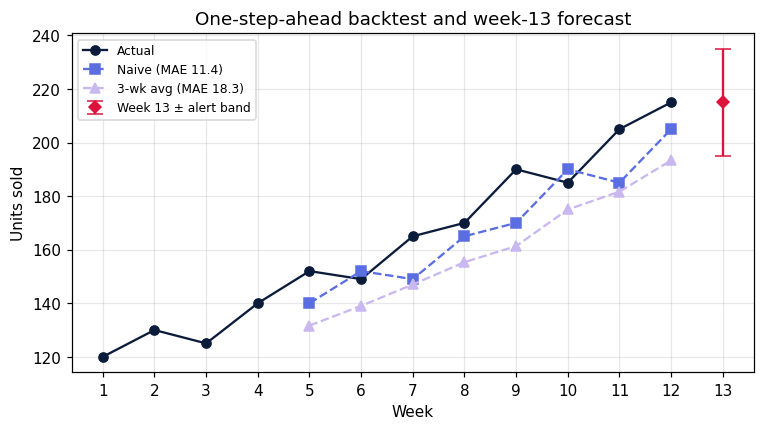

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 13), SALES, "o-", label="Actual", color="#0B1B3A")
ax.plot(bt["Week"], bt["Naive forecast"], "s--", label=f"Naive (MAE {s['naive_mae']:.1f})", color="#5B6EE1")
ax.plot(bt["Week"], bt["3-week average forecast"], "^--", label=f"3-wk avg (MAE {s['avg_mae']:.1f})", color="#C9B8F0")
t = alert_tolerance(bt[col], 0.80)
ax.errorbar([13], [f13], yerr=[[t["half_width"]], [t["half_width"]]], fmt="D", color="crimson", capsize=5, label="Week 13 ± alert band")
ax.set_xticks(range(1, 14)); ax.set_xlabel("Week"); ax.set_ylabel("Units sold"); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title("One-step-ahead backtest and week-13 forecast"); plt.show()

## Tests

In [8]:
suite = unittest.defaultTestLoader.discover("../tests", pattern="test_q3*.py", top_level_dir="..")
res = unittest.TextTestRunner(verbosity=1).run(suite)
print("tests run:", res.testsRun, "| failures:", len(res.failures), "| errors:", len(res.errors))

tests run: 40 | failures: 0 | errors: 0


........................................
----------------------------------------------------------------------
Ran 40 tests in 0.032s

OK


## (e) Decision memo (generated from the numbers above)

In [9]:
from IPython.display import Markdown, display
display(Markdown(decision_memo(SALES, 0.80)))

# Q3 decision memo: weekly demand baseline

## Decision
Adopt **Naive last value** as the working baseline for week 13: forecast **215.0 units**.
It had the lower one-step-ahead MAE over the 8 backtest weeks (5-12). This is a choice between two
simple baselines on one short series. It is **not** evidence of how accurate the forecast will be.

## Evidence
| Method | Week 13 forecast | Backtest MAE | Mean signed error | Weeks it was closer |
|---|---|---|---|---|
| Naive last value | 215.0 | 11.375 | +9.38 | 8 of 8 |
| Trailing 3-week average | 201.7 | 18.333 | +18.33 | 0 of 8 |

Signed error = actual - forecast. Both mean signed errors are positive: demand kept rising, so both methods under-forecast on average.
The 3-week average lags more because it averages older, lower weeks. That lag is the likely reason it loses,
and it would reverse on a flat or mean-reverting series.

## Validation design
Expanding window, one step ahead: to score week t the methods see weeks 1..t-1 only.
Shuffling observations would let weeks after t inform the forecast of week t. As an illustration, "predicting"
each week from its two neighbours (one of which is in the future) gives MAE 8.57, lower than the honest
naive forecast here (11.38), even though it uses information no real forecast could have. Shuffling also breaks the trend and autocorrelation the methods depend on.

## Demand alert
Alert if actual demand falls outside forecast +/- **20.0 units** (the
rank-8 of 8 backtest absolute errors of the chosen method, target 80%).
For week 13: 195.0 to 235.0 units.
With 8 errors this reaches the minimum sample for a finite-sample coverage statement, but only if future errors resemble past ones (doubtful on a trending series).

## Limitations
- 8 errors from one series: MAE, the band and the baseline ranking could all change with a few more weeks.
  No significance test is meaningful at this size.
- The band is symmetric, but errors here are one-sided (bias +9.4 for naive). Under a continuing trend
  a symmetric band will flag rises late and miss that the forecast is systematically low.
- The rule assumes future errors look like past errors (exchangeability). Trend changes, promotions,
  stock-outs (sales are not demand) and holidays break this.
- Week numbers are assumed to be consecutive weeks. No timestamps were supplied, so missing or
  duplicate calendar dates cannot be detected on this data; the detector is tested on separate dated inputs.
- Recommendation: use the baseline now, record each new week's error, and re-run the comparison (and test
  a trend-aware challenger such as drift or Holt) once there are enough weeks to support it.
